# Human Action Recognition
### Locate the Person (Pretrained) + Classify the Action (Custom-Trained CNN)

This project follows the same pattern as the cats-vs-dogs project: a **pretrained model finds the person** in a photo, and a **CNN we train ourselves decides what action they're doing**. The pretrained model is never trained here, and its own classification guess is discarded entirely - only its bounding box is used.

1. **Section 1 — Imports and Setup**
2. **Section 2 — Data Extraction and Preprocessing** (streams a balanced set of action images from Hugging Face Hub)
3. **Section 3 — Building Our Own CNN**
4. **Section 4 — Training and Evaluation**
5. **Section 5 — Loading a Pretrained Person Locator**
6. **Section 6 — Combining Both: Locate the Person, Classify the Action**
7. **Section 7 — The Dashboard**, running and displayed inline at the end

**The 15 action classes:** calling, clapping, cycling, dancing, drinking, eating, fighting, hugging, laughing, listening to music, running, sitting, sleeping, texting, using a laptop.


## Why Split Locating and Classifying?

- A pretrained detector (SSD MobileNet V2, trained on COCO) already knows how to find people in a photo — COCO is a huge dataset with hand-drawn boxes around people, among 79 other object categories.
- No such box-labeled dataset exists for "a person doing 15 specific everyday actions" — the Human Action Recognition dataset used here only labels the *action*, not *where* the person is in the frame.
- So we reuse the pretrained model purely to answer "where is the person," and train our own CNN to answer "what are they doing," using only the cropped region the locator finds.


## Section 1 — Imports and Setup


In [6]:
# Fast dependency check: reads each package's installed metadata instead of
# actually importing it - importing a library just to check "is it
# installed" is itself slow, especially for TensorFlow.
from importlib import metadata  # lets us check a package's installed version without importing the package itself
import subprocess  # lets us run "pip install" as a command from within Python
import sys  # gives us sys.executable, the exact Python interpreter running this notebook

required_packages = [
    "tensorflow", "tensorflow-hub", "datasets", "matplotlib", "numpy",
    "pillow", "flask", "seaborn", "scikit-learn",
]  # every package this notebook needs, by their pip install names

missing = []  # will collect the names of any packages not currently installed
for package_name in required_packages:  # check each required package one at a time
    try:
        metadata.version(package_name)  # raises if the package isn't installed
    except metadata.PackageNotFoundError:
        missing.append(package_name)  # not installed - add it to the install list

if missing:
    print(f"Installing missing packages: {missing}")  # tell the user what's about to happen
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)  # run pip install using this exact Python environment
    print("Done.")
else:
    print("All required packages are already installed - nothing to do.")


All required packages are already installed - nothing to do.


In [7]:
import base64  # encodes image bytes as text, used later to embed images directly in HTML
import io  # lets us treat in-memory bytes like a file (no disk writes needed)
import threading  # runs the dashboard's web server without blocking the rest of the notebook

import numpy as np  # array math
import matplotlib.pyplot as plt  # plotting images and training curves
import tensorflow as tf  # core deep learning framework - builds and trains our CNN
import tensorflow_hub as hub  # loads the pretrained locator in one line
from PIL import Image, ImageDraw, ImageFont  # drawing bounding boxes and labels on images
from IPython.display import IFrame, display  # embeds the dashboard inside this notebook

print("TensorFlow version:", tf.__version__)  # confirm which TensorFlow version is active
print("GPU available:", tf.config.list_physical_devices('GPU'))  # confirm whether training will use a GPU

try:
    import google.colab  # only importable inside an actual Colab environment
    IN_COLAB = True  # import succeeded - we are in Colab
except ImportError:
    IN_COLAB = False  # import failed - we are in VS Code, Jupyter, or similar

print("Running in Colab:", IN_COLAB)  # confirm which display method the dashboard section will use


TensorFlow version: 2.21.0
GPU available: []
Running in Colab: False


## Section 2 — Data Extraction and Preprocessing

We stream the **Human Action Recognition** dataset from Hugging Face Hub (15 classes, ~12,600 training images total). We only pull a small, balanced slice — not the whole dataset.

**A lesson learned the hard way on a previous project:** some Hugging Face datasets are ordered by class internally. A naive `.take(N)` can silently grab almost entirely one class. So instead of a positional slice, we explicitly collect an *equal number of examples per class* before stopping, and verify the result — the same defensive approach that fixed a real, broken training run last time.


In [8]:
CLASS_NAMES = [
    "calling", "clapping", "cycling", "dancing", "drinking", "eating",
    "fighting", "hugging", "laughing", "listening_to_music", "running",
    "sitting", "sleeping", "texting", "using_laptop",
]  # the 15 action classes, in the order the dataset itself uses
NUM_CLASSES = len(CLASS_NAMES)  # 15 - sizes the model's output layer
IMG_SIZE = 128  # every photo gets resized to 128 x 128 before going into the CNN

N_TRAIN_PER_CLASS = 100  # 100 x 15 = 1,500 training images
N_VAL_PER_CLASS = 20     # 20 x 15 = 300 validation images


def load_balanced_examples(n_train_per_class, n_val_per_class):
    """Streams the dataset and collects an EQUAL number of examples per
    class for training and validation, stopping as soon as every class has
    enough - never downloading the full ~12,600 image dataset."""
    from datasets import load_dataset  # imported here so the rest of the notebook works even if this call fails

    print("Streaming dataset from Hugging Face Hub (only downloads what we use)...")  # let the user know a network call is starting
    stream = load_dataset("Bingsu/Human_Action_Recognition", split="train", streaming=True)  # opens a lazy connection - nothing downloaded yet

    per_class_train = {i: [] for i in range(NUM_CLASSES)}  # one empty bucket per class, for training examples
    per_class_val = {i: [] for i in range(NUM_CLASSES)}  # one empty bucket per class, for validation examples

    for example in stream:  # pulls one example at a time from the network as needed
        label = example["labels"]  # integer 0-14 identifying the action class
        if len(per_class_train[label]) < n_train_per_class:
            per_class_train[label].append(example)  # still need more of this class for training - keep it
        elif len(per_class_val[label]) < n_val_per_class:
            per_class_val[label].append(example)  # training quota met - use it for validation instead

        train_full = all(len(v) >= n_train_per_class for v in per_class_train.values())  # True once every class has enough training examples
        val_full = all(len(v) >= n_val_per_class for v in per_class_val.values())  # True once every class has enough validation examples
        if train_full and val_full:
            break  # stop as soon as every class has enough for both splits

    train_examples = [ex for bucket in per_class_train.values() for ex in bucket]  # flatten the 15 per-class buckets into one list
    val_examples = [ex for bucket in per_class_val.values() for ex in bucket]  # flatten the 15 per-class buckets into one list

    import random  # only needed here, for shuffling these two small lists
    random.Random(42).shuffle(train_examples)  # shuffle in place with a fixed seed for reproducibility
    random.Random(42).shuffle(val_examples)  # shuffle in place with a fixed seed for reproducibility

    return train_examples, val_examples  # both are now balanced and well-mixed


try:
    train_examples, val_examples = load_balanced_examples(N_TRAIN_PER_CLASS, N_VAL_PER_CLASS)  # do the actual streaming + balancing work
    print(f"Got {len(train_examples)} training and {len(val_examples)} validation examples.")  # confirm how much data we ended up with

    # Verification step: confirm the classes actually came out balanced.
    import collections  # provides Counter, an easy way to tally class counts
    train_counts = collections.Counter(ex["labels"] for ex in train_examples)  # count how many examples belong to each class
    print("Training class balance:", {CLASS_NAMES[k]: v for k, v in sorted(train_counts.items())})  # print counts using readable class names
except Exception as e:
    print(f"Automatic download failed: {e}")  # show the actual error so it can be diagnosed
    print()
    print("MANUAL FALLBACK: download the dataset from Kaggle instead:")
    print("  https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset")
    raise  # stop execution here rather than silently continuing with no data


Streaming dataset from Hugging Face Hub (only downloads what we use)...
Got 1500 training and 300 validation examples.
Training class balance: {'calling': 100, 'clapping': 100, 'cycling': 100, 'dancing': 100, 'drinking': 100, 'eating': 100, 'fighting': 100, 'hugging': 100, 'laughing': 100, 'listening_to_music': 100, 'running': 100, 'sitting': 100, 'sleeping': 100, 'texting': 100, 'using_laptop': 100}


In [9]:
def examples_to_arrays(examples, img_size):
    """Converts Hugging Face examples into resized, normalized numpy arrays."""
    images, labels = [], []  # will hold one image and one label per example
    for example in examples:  # process each example one at a time
        img = example["image"].convert("RGB").resize((img_size, img_size))  # force 3 color channels and a fixed size
        images.append(np.array(img, dtype=np.float32) / 255.0)  # normalize pixel values to [0, 1]
        labels.append(example["labels"])  # keep the label as a plain integer (0-14)
    return np.array(images), np.array(labels)  # stack the lists into single numpy arrays


X_train, y_train = examples_to_arrays(train_examples, IMG_SIZE)  # convert all training examples at once
X_val, y_val = examples_to_arrays(val_examples, IMG_SIZE)  # convert all validation examples at once

BATCH_SIZE = 32  # number of images processed together in one training step

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))  # turn the numpy arrays into a tf.data.Dataset
    .shuffle(1000, seed=42)  # randomize the order so the model doesn't see a fixed sequence every epoch
    .batch(BATCH_SIZE)  # group examples into batches for efficient training
    .prefetch(tf.data.AUTOTUNE)  # prepare the next batch while the current one is being processed
)
val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))  # turn the numpy arrays into a tf.data.Dataset
    .batch(BATCH_SIZE)  # group examples into batches (no shuffling needed for validation)
    .prefetch(tf.data.AUTOTUNE)  # prepare the next batch while the current one is being processed
)

print("Pipelines ready.")  # confirm both datasets are built and ready for training


Pipelines ready.


### Visualize the extracted data


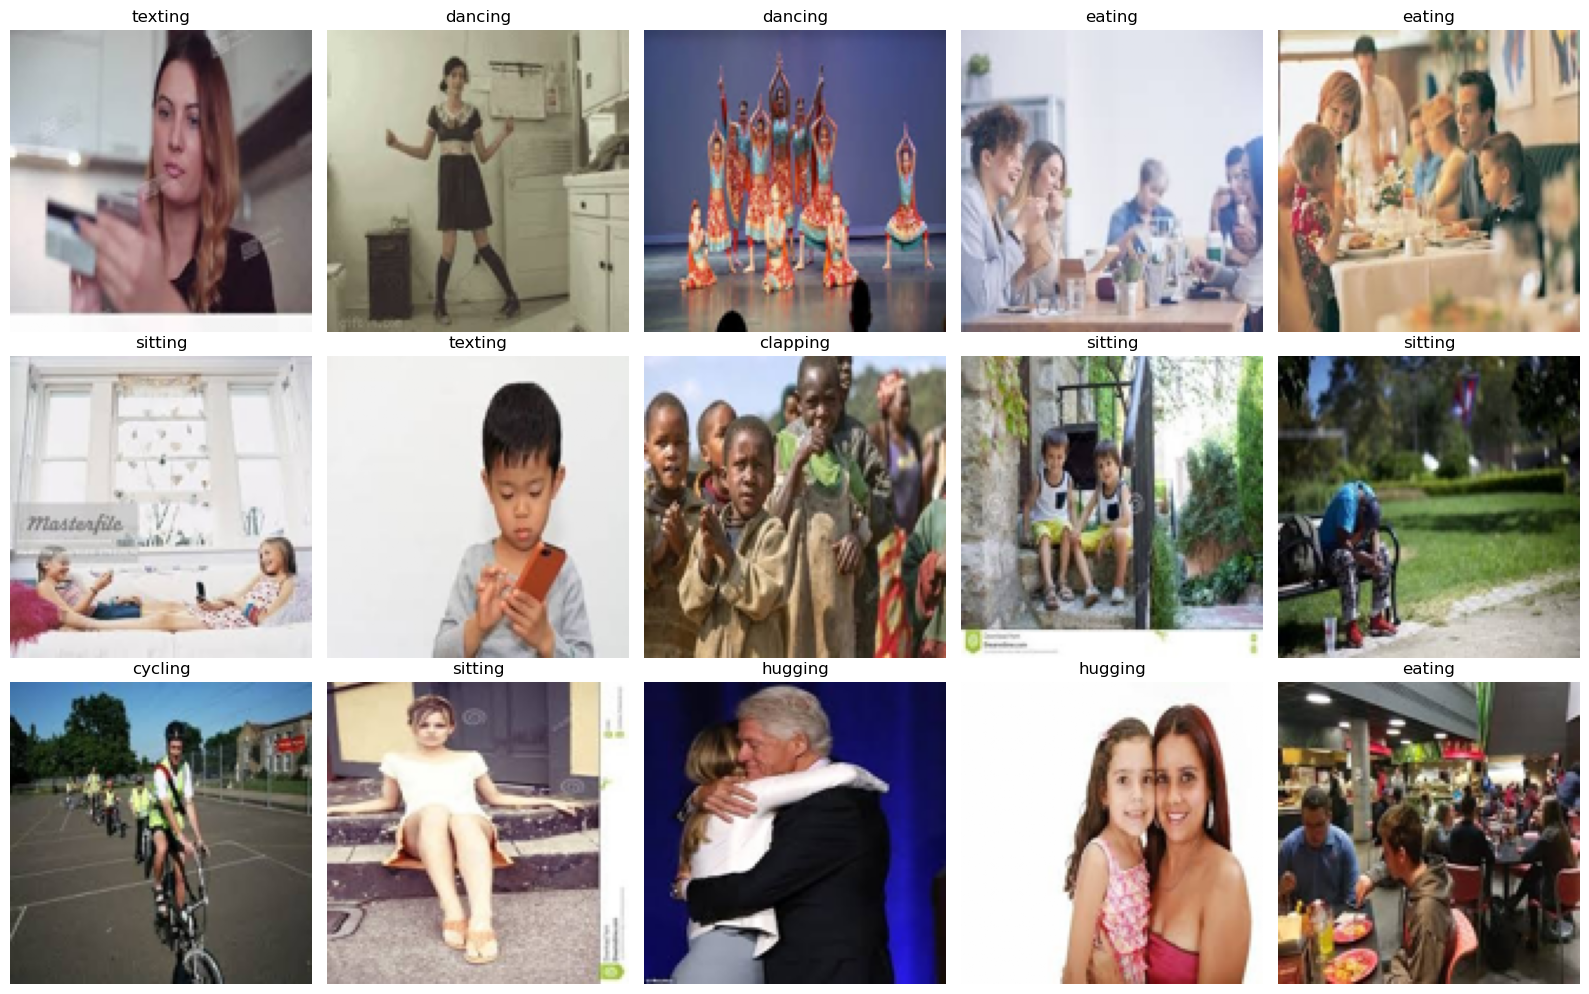

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))  # a 3x5 grid, one subplot per sample image
for ax, img, label in zip(axes.flatten(), X_train[:15], y_train[:15]):  # pair each subplot with one image and its label
    ax.imshow(img)  # display the image
    ax.set_title(CLASS_NAMES[label].replace("_", " "))  # show the readable action name as the title
    ax.axis("off")  # hide the x/y axis ticks, since they add no useful information here
plt.tight_layout()  # avoid overlapping titles/images
plt.show()  # render the figure


## Section 3 — Building Our Own CNN

Same architecture pattern as before, extended for **15-way classification** instead of binary: the output layer now has 15 softmax units instead of 1 sigmoid unit, and the loss changes to `sparse_categorical_crossentropy` (labels are plain integers 0-14, not one-hot encoded).


In [11]:
def build_cnn(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),  # declares the expected input shape

        tf.keras.layers.Conv2D(32, 3, activation="relu"),  # first convolution block: 32 filters, 3x3 kernel
        tf.keras.layers.MaxPooling2D(),  # halves the spatial size, keeping the strongest features

        tf.keras.layers.Conv2D(64, 3, activation="relu"),  # second convolution block: more filters, deeper features
        tf.keras.layers.MaxPooling2D(),  # halves the spatial size again

        tf.keras.layers.Conv2D(128, 3, activation="relu"),  # third convolution block: even more filters
        tf.keras.layers.MaxPooling2D(),  # halves the spatial size a third time

        tf.keras.layers.Flatten(),  # turns the 3D feature maps into a single 1D vector
        tf.keras.layers.Dense(256, activation="relu"),  # fully connected layer combining all extracted features
        tf.keras.layers.Dropout(0.4),  # randomly disables neurons during training only, to reduce overfitting
        tf.keras.layers.Dense(num_classes, activation="softmax"),  # 15-way classification
    ])

    model.compile(
        optimizer="adam",  # a reliable, widely used default optimizer
        loss="sparse_categorical_crossentropy",  # integer labels, not one-hot
        metrics=["accuracy"],  # track classification accuracy during training and validation
    )
    return model  # hand back the fully built and compiled model


action_model = build_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)  # build the CNN for our chosen image size and class count
action_model.summary()  # print every layer, its output shape, and its parameter count


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,519,887 (24.87 MB)

 Trainable params: 6,519,887 (24.87 MB)

 Non-trainable params: 0 (0.00 B)

## Section 4 — Training and Evaluation

For the **live class demo**, this trains on a relatively small, balanced slice for a handful of epochs. With 15 classes to distinguish (versus 2 for cats/dogs), expect noticeably lower accuracy than the binary project at this scale - that's expected, not a bug. Increase `N_TRAIN_PER_CLASS` and `EPOCHS` after class for a stronger model.


In [12]:
EPOCHS = 50  # how many full passes through the training data to run

history = action_model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS)  # run the training loop; history records per-epoch accuracy/loss


Epoch 1/50


C:\Users\Pavana NA\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 329ms/step - accuracy: 0.0700 - loss: 2.7551 - val_accuracy: 0.0967 - val_loss: 2.6921
Epoch 2/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 306ms/step - accuracy: 0.1327 - loss: 2.6263 - val_accuracy: 0.1300 - val_loss: 2.6399
Epoch 3/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 302ms/step - accuracy: 0.1907 - loss: 2.4862 - val_accuracy: 0.1467 - val_loss: 2.6293
Epoch 4/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 294ms/step - accuracy: 0.2973 - loss: 2.1690 - val_accuracy: 0.1267 - val_loss: 2.6868
Epoch 5/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 291ms/step - accuracy: 0.4873 - loss: 1.7084 - val_accuracy: 0.1633 - val_loss: 2.8649
Epoch 6/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 292ms/step - accuracy: 0.6313 - loss: 1.1845 - val_accuracy: 0.1600 - val_loss: 3.2271
Epoch 7/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 291ms/step - accuracy: 0.7820 - loss: 0.7278 - val_accuracy: 0.1733 - val_loss: 3.7052
Epoch 8/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 13s 283ms/step - accuracy: 0.8780 - loss: 0.4327 - val_accuracy: 0.200

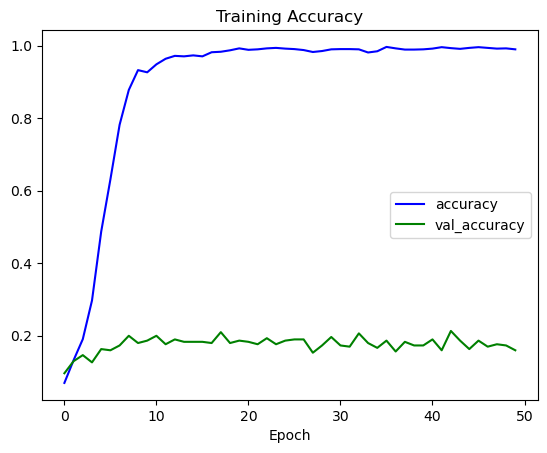

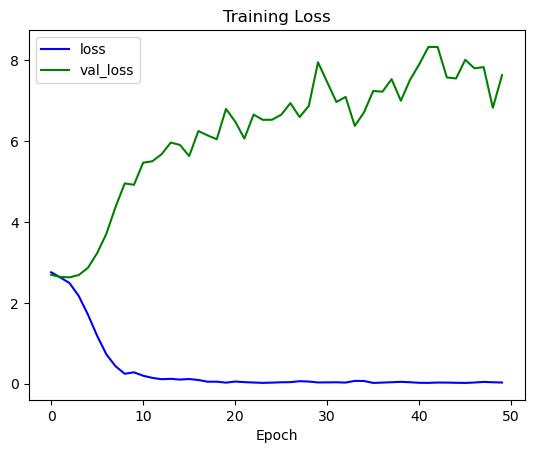

In [22]:
def plot_metrics(metric_name, title):
    plt.plot(history.history[metric_name], label=metric_name, color="blue")  # training curve
    plt.plot(history.history["val_" + metric_name], label="val_" + metric_name, color="green")  # validation curve
    plt.title(title)
    plt.xlabel("Epoch")
    plt.legend()  # show which color corresponds to which line
    plt.show()  # render the chart


plot_metrics("accuracy", "Training Accuracy")  # plot how accuracy changed over training
plot_metrics("loss", "Training Loss")  # plot how loss changed over training


                    precision    recall  f1-score   support

           calling       0.07      0.10      0.09        20
          clapping       0.21      0.15      0.18        20
           cycling       0.47      0.45      0.46        20
           dancing       0.09      0.20      0.13        20
          drinking       0.25      0.05      0.08        20
            eating       0.14      0.10      0.12        20
          fighting       0.16      0.25      0.20        20
           hugging       0.12      0.10      0.11        20
          laughing       0.17      0.10      0.12        20
listening_to_music       0.07      0.10      0.09        20
           running       0.18      0.10      0.13        20
           sitting       0.14      0.10      0.12        20
          sleeping       0.50      0.30      0.38        20
           texting       0.13      0.20      0.16        20
      using_laptop       0.08      0.10      0.09        20

          accuracy                    

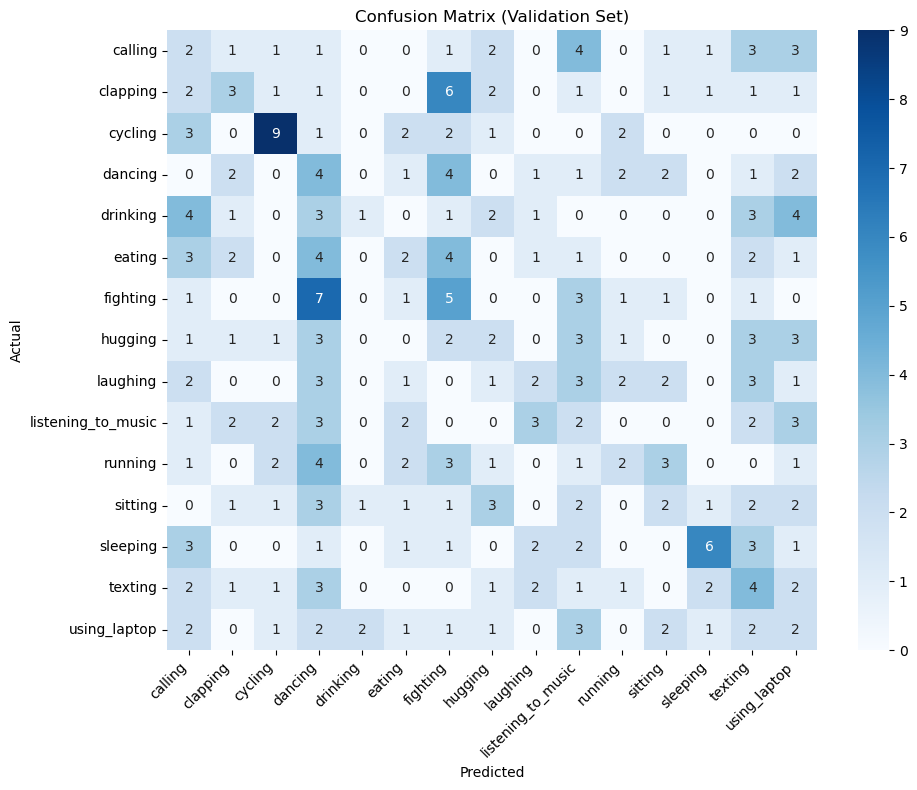

In [23]:
from sklearn.metrics import confusion_matrix, classification_report  # richer evaluation tools than plain accuracy
import seaborn as sns  # nicer heatmap styling

y_pred = np.argmax(action_model.predict(X_val, verbose=0), axis=1)  # convert softmax probabilities into a single predicted class per image

print(classification_report(y_val, y_pred, target_names=CLASS_NAMES, zero_division=0))  # per-class precision/recall/F1 in one readable table

cm = confusion_matrix(y_val, y_pred, labels=list(range(NUM_CLASSES)))  # 15x15 grid of true class vs predicted class counts
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)  # draw the matrix with counts labeled in each cell
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")  # angle the class names so they don't overlap
plt.title("Confusion Matrix (Validation Set)")
plt.tight_layout()
plt.show()


## Section 5 — Loading a Pretrained Person Locator

**SSD MobileNet V2**, trained on COCO, used only to find *where* the person is. We deliberately ignore whatever class label it guesses beyond "is this a person" - our own CNN from Sections 3-4 makes the actual action call.


In [24]:
LOCATOR_URL = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"  # the pretrained model's address on TensorFlow Hub
PERSON_CLASS_ID = 1  # COCO class id for "person"
LOCATOR_THRESHOLD = 0.4  # minimum confidence required before trusting a detected box

print("Loading pretrained locator... (first run may take a minute or two)")  # first run downloads and caches the model
locator = hub.load(LOCATOR_URL)  # download (or load from cache) and prepare the model for use
print("Locator loaded successfully")  # confirm the model is ready


def find_person_box(image_np):
    """Runs the pretrained locator and returns the single most confident
    person box, or None if no person was found confidently enough."""
    input_tensor = tf.convert_to_tensor(image_np)[tf.newaxis, ...]  # add the batch dimension the model expects
    detections = locator(input_tensor)  # run the pretrained model on this one image

    boxes = detections["detection_boxes"][0].numpy()  # (ymin, xmin, ymax, xmax), normalized
    classes = detections["detection_classes"][0].numpy().astype(int)  # COCO class id for each detected box
    scores = detections["detection_scores"][0].numpy()  # confidence score for each detected box

    keep = (scores >= LOCATOR_THRESHOLD) & (classes == PERSON_CLASS_ID)  # True only for confident person detections
    if not np.any(keep):
        return None  # no confident person detection found

    best_index = np.argmax(scores * keep)  # the single most confident person box
    ymin, xmin, ymax, xmax = boxes[best_index]  # unpack that box's four coordinates
    return float(ymin), float(xmin), float(ymax), float(xmax)  # return as plain Python floats


Loading pretrained locator... (first run may take a minute or two)
Locator loaded successfully


## Section 6 — Combining Both: Locate the Person, Classify the Action

1. Run the **pretrained locator** to find the person's box.
2. **Crop** the image to that box.
3. Resize and normalize the crop the same way we did for training.
4. Run **our own trained CNN** on the crop to decide which action it is.
5. Draw the box and label using **our CNN's** prediction, not the locator's.

If the locator finds nothing confident, we fall back to classifying the whole photo.


In [25]:
def draw_label_box(image_np, box, display_str):
    image_pil = Image.fromarray(np.uint8(image_np)).convert("RGB")  # convert to a drawable, 3-channel PIL image
    draw = ImageDraw.Draw(image_pil)  # a "pen" object that can draw directly onto this image
    img_w, img_h = image_pil.size  # actual pixel dimensions of the image

    if box is not None:
        ymin, xmin, ymax, xmax = box  # unpack the normalized (0-1) box coordinates
        left, right, top, bottom = xmin * img_w, xmax * img_w, ymin * img_h, ymax * img_h  # convert to pixel positions
        draw.line([(left, top), (left, bottom), (right, bottom), (right, top), (left, top)], width=3, fill="lime")  # draw the box outline
        text_anchor = (left, max(top - 24, 0))  # place the label just above the box, but never off-screen
    else:
        text_anchor = (8, 8)  # no box to anchor to - place the label near the top-left corner instead

    try:
        font = ImageFont.truetype("arial.ttf", 20)  # prefer a nicer, larger system font if available
    except IOError:
        font = ImageFont.load_default()  # fall back to PIL's built-in font if Arial isn't installed

    bbox = draw.textbbox(text_anchor, display_str, font=font)  # measure how big the label text will be
    draw.rectangle(bbox, fill="lime")  # solid background tag so the text stays readable over any photo
    draw.text(text_anchor, display_str, fill="black", font=font)  # draw the label text on top of the background tag
    return np.array(image_pil)  # convert back to numpy so it can be plotted/embedded like any other image


def classify_action(image_np):
    img_h, img_w = image_np.shape[0], image_np.shape[1]  # actual pixel dimensions of the input photo
    box = find_person_box(image_np)  # ask the pretrained locator where the person is (or None)

    if box is not None:
        ymin, xmin, ymax, xmax = box  # unpack the normalized (0-1) box coordinates
        top, bottom = int(ymin * img_h), int(ymax * img_h)  # vertical crop boundaries in pixels
        left, right = int(xmin * img_w), int(xmax * img_w)  # horizontal crop boundaries in pixels
        crop = image_np[top:bottom, left:right]  # slice out just the located region
    else:
        crop = image_np  # fall back to the whole photo if nothing confident was located

    crop_resized = tf.image.resize(crop, (IMG_SIZE, IMG_SIZE))  # match the size our CNN was trained on
    crop_resized = tf.cast(crop_resized, tf.float32) / 255.0  # normalize pixel values to [0, 1]
    crop_batch = tf.expand_dims(crop_resized, axis=0)  # add the batch dimension the model expects

    predictions = action_model.predict(crop_batch, verbose=0)[0]  # softmax probabilities across all 15 classes
    predicted_index = int(np.argmax(predictions))  # index of the highest-scoring class
    label = CLASS_NAMES[predicted_index]  # translate that index into a readable action name
    confidence = float(predictions[predicted_index])  # the model's confidence in that prediction

    display_str = f"{label}: {confidence:.2f}"  # text to draw on the image, e.g. "running: 0.87"
    annotated = draw_label_box(image_np, box, display_str)  # draw the box (if any) and label on the original photo

    detection = {"label": label, "confidence": round(confidence, 3), "box_found": box is not None}  # plain summary of the result
    return annotated, detection  # hand back both the annotated image and the result details


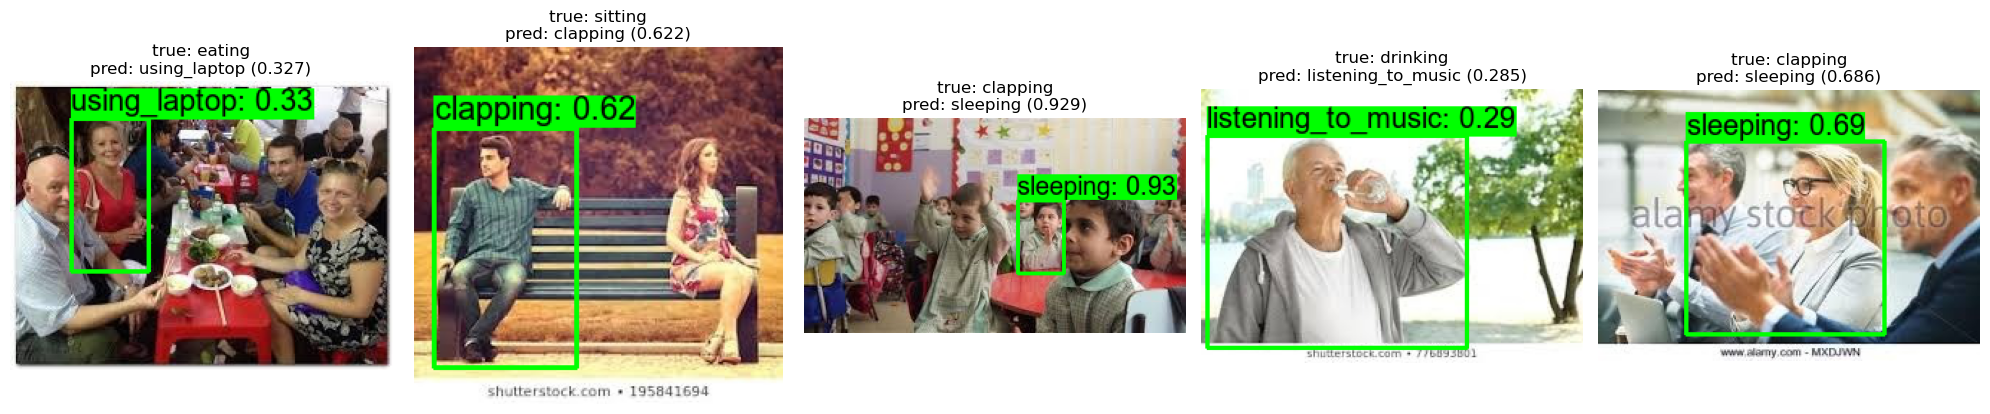

In [26]:
# Try the full pipeline on a few real validation photos.
fig, axes = plt.subplots(1, 5, figsize=(20, 4))  # one subplot per sample photo
for ax, example in zip(axes, val_examples[:5]):  # pair each subplot with one validation example
    image = np.array(example["image"].convert("RGB"))  # convert the PIL image to a plain numpy array
    annotated, detection = classify_action(image)  # run the full locate + classify pipeline
    true_label = CLASS_NAMES[example["labels"]]  # the actual correct label for this photo
    ax.imshow(annotated)  # display the annotated (boxed and labeled) result
    ax.set_title(f"true: {true_label}\npred: {detection['label']} ({detection['confidence']})")  # show both true and predicted labels
    ax.axis("off")  # hide the x/y axis ticks
plt.tight_layout()  # avoid overlapping titles/images
plt.show()  # render the figure


## Section 7 — The Dashboard

Everything from Sections 5-6 (`find_person_box`, `classify_action`) is reused directly here — the dashboard adds nothing new on the detection or classification side.


In [27]:
def image_to_data_uri(image_np):
    image_pil = Image.fromarray(np.uint8(image_np))  # convert the numpy array into a PIL image
    buffer = io.BytesIO()  # an in-memory "file" to hold the encoded image bytes
    image_pil.save(buffer, format="PNG")  # write the image into that in-memory buffer as PNG
    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")  # turn the raw bytes into a text string
    return f"data:image/png;base64,{encoded}"  # a data URI a browser can display directly, no file needed


In [28]:
from flask import Flask, render_template_string, request  # the web framework powering the dashboard

flask_app = Flask(__name__)  # create the web application object
ALLOWED_EXTENSIONS = {"png", "jpg", "jpeg", "webp"}  # file types the upload form will accept


def allowed_file(filename):
    return "." in filename and filename.rsplit(".", 1)[1].lower() in ALLOWED_EXTENSIONS  # True only if the extension is in our allowed set


PAGE_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Human Action Recognition</title>
    <style>
        body { font-family: -apple-system, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;
               background: #f6f7f9; color: #1f2937; margin: 0; }
        .topbar { text-align: center; padding: 24px 16px 16px; }
        .topbar h1 { margin: 4px 0; font-size: 24px; }
        main { max-width: 560px; margin: 0 auto; padding: 0 16px 32px; }
        .card { background: #fff; border: 1px solid #e5e7eb; border-radius: 12px; padding: 20px; margin-top: 16px; text-align: center; }
        .file-label { display: block; border: 2px dashed #e5e7eb; border-radius: 10px; padding: 24px 16px; cursor: pointer; color: #6b7280; }
        .file-label input { display: none; }
        button { margin-top: 14px; background: #7c3aed; color: white; border: none; padding: 9px 24px; border-radius: 8px; font-size: 15px; cursor: pointer; }
        .result-image { max-width: 100%; border-radius: 10px; }
        .notice { color: #b45309; margin-top: 12px; font-size: 13px; }
    </style>
</head>
<body>
    <header class="topbar"><h1>Human Action Recognition</h1></header>
    <main>
        <section class="card">
            <form action="/predict" method="post" enctype="multipart/form-data">
                <label class="file-label"><span>Click to choose an image</span>
                    <input type="file" name="photo" accept=".png,.jpg,.jpeg,.webp" required></label>
                <button type="submit">Detect</button>
            </form>
            {% if error %}<p class="notice">{{ error }}</p>{% endif %}
        </section>
        {% if result_image %}
        <section class="card">
            <h2>Result</h2>
            <img src="{{ result_image }}" class="result-image">
            <p><strong>{{ detection.label|capitalize }}</strong> ({{ (detection.confidence*100)|round(1) }}%)</p>
        </section>
        {% endif %}
    </main>
</body>
</html>
"""


@flask_app.route("/", methods=["GET"])  # the homepage - shown when someone first opens the dashboard
def index():
    return render_template_string(PAGE_TEMPLATE, result_image=None, detection=None, error=None)  # render the empty upload form


@flask_app.route("/predict", methods=["POST"])  # handles the form submission when a photo is uploaded
def predict():
    if "photo" not in request.files or request.files["photo"].filename == "":
        return render_template_string(PAGE_TEMPLATE, result_image=None, detection=None, error="Please choose an image file first.")  # no file was actually selected

    file = request.files["photo"]  # the uploaded file object
    if not allowed_file(file.filename):
        return render_template_string(PAGE_TEMPLATE, result_image=None, detection=None, error="Please upload a PNG, JPG, JPEG, or WEBP image.")  # reject unsupported file types

    image = Image.open(file.stream).convert("RGB")  # open the upload directly from memory
    image_np = np.array(image)  # convert to a numpy array for our pipeline functions

    annotated_np, detection = classify_action(image_np)  # locate the person and classify the action
    result_image = image_to_data_uri(annotated_np)  # encode the annotated result for embedding in HTML

    return render_template_string(PAGE_TEMPLATE, result_image=result_image, detection=detection, error=None)  # render the page with the result

print("Flask app defined.")  # confirm the app and its routes are ready, before we start the server


Flask app defined.


In [30]:
def run_flask_app():
    flask_app.run(host="127.0.0.1", port=5000, debug=False, use_reloader=False)  # start the server, blocking this thread only


dashboard_thread = threading.Thread(target=run_flask_app, daemon=True)  # prepare a background thread to run the server
dashboard_thread.start()  # start the server without blocking the rest of the notebook

print("Dashboard starting...")  # give the server a moment to come up before we try to display it

if IN_COLAB:
    from google.colab import output as colab_output  # only available inside Colab
    colab_output.serve_kernel_port_as_iframe(5000, height=650)  # Colab-specific way to proxy and display the local port
else:
    display(IFrame(src="http://127.0.0.1:5000", width="100%", height=650))  # embed the dashboard directly in the notebook output


Dashboard starting...


 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


**Upload a photo of someone doing one of the 15 actions above.** If the dashboard area looks blank, re-run the cell once — the server sometimes needs a moment to finish starting.


## Wrap Up and Next Steps

**What we built:**
- A real, balanced data pipeline over 15 action classes, streamed from Hugging Face Hub
- A custom CNN trained from scratch for 15-way action classification
- A pretrained locator, used only to find the person - never to classify the action
- A combined pipeline and a live dashboard using it

**Where to go from here:**
- Increase `N_TRAIN_PER_CLASS` and `EPOCHS` for a meaningfully more accurate model - 15 classes need more data per class than a 2-class problem to reach comparable accuracy.
- Look at the confusion matrix for classes the model confuses most often (e.g. "texting" vs "using_laptop") and consider whether more distinguishing training examples would help.
- Try a pretrained image backbone (e.g. MobileNetV2 via transfer learning) instead of a CNN trained fully from scratch, and compare accuracy at the same training set size.
